# Notebook 0 · Data understanding

**Purpose:** understand the SBA 7(a) FOIA file (FY2010-FY2019 approvals, status as of 31 Mar 2026) before any analysis, and record every data-cleaning decision.

**Inputs:** `data/raw/foia-7a-fy2010-fy2019-asof-260331.csv`, `docs/7a_504_foia_data_dictionary-asof-260331.xlsx`
**Outputs:** `data/processed/loans_clean.parquet`

**Sections**
1. Load data and dictionary
2. What one row looks like
3. Column profile and missing values
4. Volume, status and key numeric fields
5. Sanity checks (does the data contradict itself?)
6. Lenders: how concentrated is the market?
7. Cleaning decisions and the clean file

In [18]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the shared helpers in /common importable from this notebook
sys.path.insert(0, str(Path("../..").resolve()))
from common.data import load_raw, clean

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)

## 1. Load data and dictionary
`load_raw()` (in `common/data.py`) reads the CSV, lowercases column names, trims text, and converts the four date columns to real dates. It does **not** remove any rows.

In [19]:
df = load_raw()
print("Rows, columns:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

# Data dictionary: sheet "7(a) Data Dictionary" (the other sheet is for the 504 program)
df_dict = pd.read_excel("../../docs/7a_504_foia_data_dictionary-asof-260331.xlsx",
                        sheet_name="7(a) Data Dictionary").iloc[:, :2]
dd = dict(zip(df_dict["Field Name"].str.strip().str.lower(), df_dict["Definition"]))

# Does every column in the CSV have a definition?
print("Columns without a definition:", [c for c in df.columns if c not in dd])

Rows, columns: (545751, 43)
Memory: 338 MB
Columns without a definition: []


## 2. What one row looks like
One row = one approved 7(a) loan. The example below is a charged-off franchise loan chosen because most of its columns are filled in.

In [20]:
row = df[(df["loanstatus"] == "CHGOFF") & df["franchisename"].notna() & df["soldsecmrktind"].notna()].iloc[0]

one_row = pd.DataFrame({
    "value": row.astype(str),
    "definition": pd.Series(dd).reindex(row.index).astype(str).str.slice(0, 120),
})
with pd.option_context("display.max_rows", 150):
    display(one_row)

# Three numbers worth deriving from a single loan
print(f"SBA guarantee share : {row['sbaguaranteedapproval'] / row['grossapproval']:.0%}")
print(f"Months to charge-off: {(row['chargeoffdate'] - row['approvaldate']).days / 30.4:.0f}")
print(f"Loss severity       : {row['grosschargeoffamount'] / row['grossapproval']:.0%} of approved amount")

,value,definition
asofdate,3/31/2026,Date when the data was recorded
program,7A,Indicator of whether loan was approved under SBA's 7(a) or 504 loan program
locationid,41195.0,SBA's unique lender ID code
borrname,"Campbell Five Enterprises, LLC",Borrower name
borrstreet,464 Old Smizer Mill,Borrower street address
borrcity,Fenton,Borrower city
borrstate,MO,Borrower state
borrzip,63026,Borrower zip code
bankname,Midwest Regional Bank,Name of the bank that the loan is currently assigned to
bankfdicnumber,8889.0,The Federal Depository Insurance Corporation certificate ID of the lender


SBA guarantee share : 75%
Months to charge-off: 32
Loss severity       : 72% of approved amount


## 3. Column profile and missing values
Blank values are not always "bad data". `chargeoffdate` is only filled for charged-off loans, `franchisename` only for franchises, `soldsecmrktind` only if the loan was sold. We read each blank in that light.

In [21]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
profile

,dtype,missing_%,unique,example
asofdate,str,0.0,1,3/31/2026
program,str,0.0,1,7A
locationid,float64,0.0,3131,19845.0
borrname,str,0.0,433974,"Galaide Professional Services, Inc."
borrstreet,str,0.0,472658,"404 West Soledad Avenue, Suite A12"
borrcity,str,0.0,26419,HAGATNA
borrstate,str,0.0,58,GU
borrzip,str,0.0,24034,96910
bankname,str,0.0,2871,Bank of Guam
bankfdicnumber,float64,7.1,2454,20884.0


### 3a. Missing values in detail
Which columns have blanks, and are the blanks expected? A column is only a problem if it should be filled but isn't.

In [22]:
nulls = (df.isna().sum().to_frame("missing_rows")
           .assign(**{"missing_%": lambda x: (x["missing_rows"] / len(df) * 100).round(1)})
           .query("missing_rows > 0")
           .sort_values("missing_rows", ascending=False))

# Our reading of why each blank exists
reason = {
    "bankncuanumber": "Only credit unions have an NCUA charter",
    "bankfdicnumber": "Only FDIC-insured banks have one (blank for non-banks and credit unions)",
    "franchisecode": "Only franchise loans",
    "franchisename": "Only franchise loans",
    "chargeoffdate": "Only charged-off loans",
    "soldsecmrktind": "Only filled if sold on the secondary market",
    "paidinfulldate": "Only loans paid in full",
    "firstdisbursementdate": "Not available for cancelled/undisbursed loans",
}

nulls["why blank"] = nulls.index.map(lambda c: reason.get(c, "CHECK: not explained yet"))

nulls

,missing_rows,missing_%,why blank
bankncuanumber,528677,96.9,Only credit unions have an NCUA charter
chargeoffdate,508499,93.2,Only charged-off loans
franchisename,498304,91.3,Only franchise loans
franchisecode,498198,91.3,Only franchise loans
soldsecmrktind,417774,76.6,Only filled if sold on the secondary market
paidinfulldate,154058,28.2,Only loans paid in full
firstdisbursementdate,67052,12.3,Not available for cancelled/undisbursed loans
bankfdicnumber,38651,7.1,Only FDIC-insured banks have one (blank for non-banks and credit unions)
businessage,1795,0.3,CHECK: not explained yet
borrname,30,0.0,CHECK: not explained yet


### 3b. Values in each categorical column
For columns with few distinct values, list every value and its count (including blanks). This tells us how each field is coded.

In [23]:
cat_cols = [c for c in df.columns if df[c].nunique() <= 25]
print("Columns with <= 25 distinct values:", cat_cols)

for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    print(f"\n=== {c}  ({df[c].nunique()} distinct, {df[c].isna().sum():,} blank)")
    print(pd.DataFrame({"rows": vc, "share_%": (vc / len(df) * 100).round(1)}).to_string())

Columns with <= 25 distinct values: ['asofdate', 'program', 'approvalfy', 'processingmethod', 'subprogram', 'fixedorvariableinterestind', 'businesstype', 'businessage', 'loanstatus', 'revolverstatus', 'collateralind', 'soldsecmrktind']

=== asofdate  (1 distinct, 0 blank)
             rows  share_%
asofdate                  
3/31/2026  545751    100.0

=== program  (1 distinct, 0 blank)
           rows  share_%
program                 
7A       545751    100.0

=== approvalfy  (10 distinct, 0 blank)
             rows  share_%
approvalfy                
2016        64074     11.7
2015        63461     11.6
2017        62430     11.4
2018        60354     11.1
2011        53710      9.8
2014        52044      9.5
2019        51907      9.5
2010        47000      8.6
2013        46395      8.5
2012        44376      8.1

=== processingmethod  (24 distinct, 0 blank)
                                                                rows  share_%
processingmethod                               

In [24]:
# Columns with many values: see the top few only
for c in ["processingmethod", "subprogram", "businesstype", "businessage", "borrstate", "sbadistrictoffice"]:
    vc = df[c].value_counts(dropna=False)
    print(f"\n=== {c}  ({df[c].nunique()} distinct)")
    print(pd.DataFrame({"rows": vc.head(10), "share_%": (vc.head(10) / len(df) * 100).round(1)}).to_string())


=== processingmethod  (24 distinct)
                                                                rows  share_%
processingmethod                                                             
SBA Express Program                                           262849     48.2
Preferred Lenders Program                                     175694     32.2
7a General                                                     41694      7.6
Small Loan Advantage Initiative                                31522      5.8
Patriot Express Loans                                           6247      1.1
Community Advantage Initiative                                  5853      1.1
Community Express                                               5468      1.0
Standard Asset Base Working Capital Line of Credit (CAPLine)    3205      0.6
Rural Loan Initiative                                           3096      0.6
Certified Lenders Program                                       2653      0.5

=== subprogram  (17 distin

## 4. Volume, status and key numeric fields

,loans,gross_usd_bn,median_loan,avg_rate_pct
approvalfy,,,,
2010,47000,12.4,100000.0,6.42
2011,53710,19.6,125000.0,6.27
2012,44376,15.2,108000.0,6.22
2013,46395,17.9,144000.0,6.11
2014,52044,19.2,116000.0,6.03
2015,63461,23.6,116000.0,6.11
2016,64074,24.1,120000.0,6.29
2017,62430,25.4,146000.0,6.62
2018,60354,25.4,125000.0,7.27


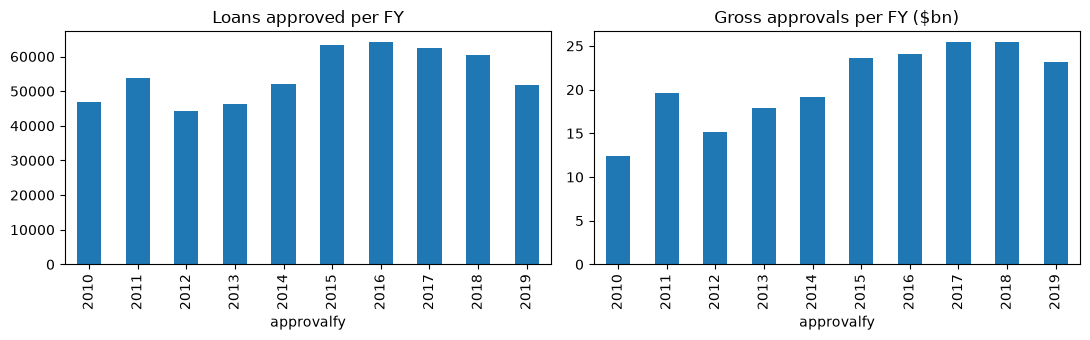

In [25]:
# Loans and dollars approved per fiscal year (US federal FY starts 1 October)

by_fy = df.groupby("approvalfy").agg(
    loans=("grossapproval", "size"),
    gross_usd_bn=("grossapproval", lambda x: round(x.sum() / 1e9, 1)),
    median_loan=("grossapproval", "median"),
    avg_rate_pct=("initialinterestrate", "mean"),
).round(2)
display(by_fy)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_fy["loans"].plot(kind="bar", ax=ax[0], title="Loans approved per FY")
by_fy["gross_usd_bn"].plot(kind="bar", ax=ax[1], title="Gross approvals per FY ($bn)")
plt.tight_layout(); plt.show()

In [26]:
# Loan status as of 31 Mar 2026

status = df["loanstatus"].value_counts()
display(pd.DataFrame({"loans": status, "share_%": (status / len(df) * 100).round(1)}))

,loans,share_%
loanstatus,,
P I F,391693,71.8
CANCLD,66740,12.2
CURR,44482,8.2
CHGOFF,30849,5.7
PURCH(NOT C/O),4703,0.9
CLSLN,2835,0.5
LIQUID,2667,0.5
DELINQ,1069,0.2
PSTDUE,547,0.1


**Reading the status codes**
- `P I F` paid in full · `CURR` current (still being repaid) · `CHGOFF` charged off
- `CANCLD` cancelled before funding: **no credit outcome**, so it is removed later
- `COMMIT` approved but not yet disbursed
- `PURCH(NOT C/O)`, `LIQUID`, `CLSLN`, `DELINQ`, `PSTDUE`, `DEFERD` distress, closure or late states

,grossapproval,sbaguaranteedapproval,initialinterestrate,terminmonths,jobssupported,grosschargeoffamount
count,545751.00,545751.00,545751.00,545751.00,545749.00,545751.00
mean,377395.86,280086.98,6.53,121.34,10.72,9678.68
std,672285.50,516874.69,1.56,79.77,20.53,81877.05
min,1000.00,500.00,0.00,0.00,0.00,0.00
1%,5000.00,2500.00,3.75,11.00,0.00,0.00
50%,125000.00,85000.00,6.00,84.00,4.00,0.00
99%,3550000.00,2700000.00,11.00,306.00,100.00,246399.16
max,5000000.00,4500000.00,13.50,847.00,2150.00,4706180.93


count    545751.000
mean          0.650
std           0.151
min           0.100
25%           0.500
50%           0.750
75%           0.750
max           1.000
Name: guarantee_pct, dtype: float64

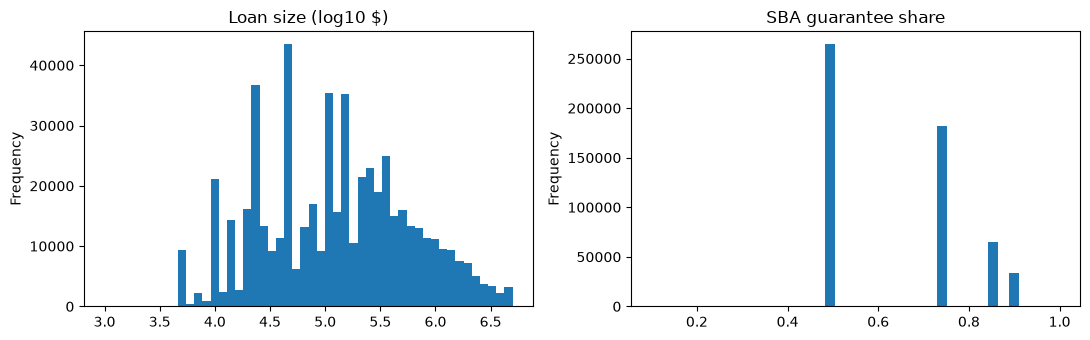

In [27]:
num_cols = ["grossapproval", "sbaguaranteedapproval", "initialinterestrate",
            "terminmonths", "jobssupported", "grosschargeoffamount"]
display(df[num_cols].describe(percentiles=[.01, .5, .99]).round(2))

# SBA guarantee as a share of the loan
df["guarantee_pct"] = df["sbaguaranteedapproval"] / df["grossapproval"]
display(df["guarantee_pct"].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
np.log10(df["grossapproval"]).plot(kind="hist", bins=50, ax=ax[0], title="Loan size (log10 $)")
df["guarantee_pct"].plot(kind="hist", bins=40, ax=ax[1], title="SBA guarantee share")
plt.tight_layout(); plt.show()

## 5. Sanity checks
Does the data contradict itself? Each check counts rows that break a rule that should hold.

In [28]:
expected_fy = np.where(df["approvaldate"].dt.month >= 10,
                       df["approvaldate"].dt.year + 1, df["approvaldate"].dt.year)

checks = pd.Series({
    "guarantee > gross approval": (df["sbaguaranteedapproval"] > df["grossapproval"]).sum(),
    "approval FY inconsistent with approval date": (expected_fy != df["approvalfy"]).sum(),
    "status P I F but no paid-in-full date": ((df["loanstatus"] == "P I F") & df["paidinfulldate"].isna()).sum(),
    "status CHGOFF but no charge-off date": ((df["loanstatus"] == "CHGOFF") & df["chargeoffdate"].isna()).sum(),
    "charge-off date but status is NOT CHGOFF": ((df["loanstatus"] != "CHGOFF") & df["chargeoffdate"].notna()).sum(),
    "first disbursement before approval": (df["firstdisbursementdate"] < df["approvaldate"]).sum(),
    "charge-off before approval": (df["chargeoffdate"] < df["approvaldate"]).sum(),
    "interest rate <= 0 or > 30": ((df["initialinterestrate"] <= 0) | (df["initialinterestrate"] > 30)).sum(),
    "term <= 0 months": (df["terminmonths"] <= 0).sum(),
    "exact duplicate rows": df.duplicated().sum(),
}).astype(int)
checks.to_frame("rows")

,rows
guarantee > gross approval,0
approval FY inconsistent with approval date,0
status P I F but no paid-in-full date,0
status CHGOFF but no charge-off date,9
charge-off date but status is NOT CHGOFF,6412
first disbursement before approval,421
charge-off before approval,0
interest rate <= 0 or > 30,8
term <= 0 months,229
exact duplicate rows,1136


### Finding: status alone undercounts charged-off loans
Some loans have a charge-off date and amount but the status is no longer `CHGOFF` (for example, paid in full after recoveries, or closed). The next cell sizes this. It decides how we define a "bad loan" in the credit analysis.

In [29]:
mismatch = df[(df["loanstatus"] != "CHGOFF") & df["chargeoffdate"].notna()]
display(mismatch["loanstatus"].value_counts().to_frame("loans"))
print(f"Charge-off $ on these loans: ${mismatch['grosschargeoffamount'].sum() / 1e6:,.0f}M")

status_only = (df["loanstatus"] == "CHGOFF").sum()
ever = (df["grosschargeoffamount"] > 0).sum()
print(f"\nCharged off by status only : {status_only:,}")
print(f"Ever charged off (amount>0): {ever:,}  (+{ever / status_only - 1:.0%})")

,loans
loanstatus,
P I F,3566
CLSLN,2835
PURCH(NOT C/O),9
DELINQ,1
LIQUID,1


Charge-off $ on these loans: $561M

Charged off by status only : 30,849
Ever charged off (amount>0): 37,251  (+21%)


## 6. Lenders: how concentrated is the market?
`bankname` is defined in the dictionary as the bank the loan is **currently assigned to**. That is usually the originator, but not always (for example after a bank failure). We keep this in mind for lender-level conclusions.

In [30]:
print("Distinct lender names :", df["bankname"].nunique())
print("Distinct location IDs :", df["locationid"].nunique())
print("Names with >1 location ID:", (df.groupby("bankname")["locationid"].nunique() > 1).sum())

lenders = (df.groupby("bankname")["grossapproval"].agg(loans="size", gross="sum")
             .sort_values("gross", ascending=False))
lenders["share_%"] = (lenders["gross"] / lenders["gross"].sum() * 100).round(1)
lenders["cum_share_%"] = lenders["share_%"].cumsum().round(1)
print("Lenders with >=100 loans:", (lenders["loans"] >= 100).sum())
lenders.head(10)

Distinct lender names : 2871
Distinct location IDs : 3131
Names with >1 location ID: 127
Lenders with >=100 loans: 488


,loans,gross,share_%,cum_share_%
bankname,,,,
Wells Fargo Bank National Association,44763,14039261400,6.8,6.8
Live Oak Banking Company,7495,9224412400,4.5,11.3
The Huntington National Bank,39297,8484800300,4.1,15.4
"U.S. Bank, National Association",25865,6258495700,3.0,18.4
"JPMorgan Chase Bank, National Association",35386,6247505200,3.0,21.4
Bank of Hope,6169,3841782800,1.9,23.3
Columbia Bank,7156,3604111900,1.7,25.0
"PNC Bank, National Association",15595,3511100900,1.7,26.7
Byline Bank,3405,3489222200,1.7,28.4


In [31]:
# Lenders with no FDIC or NCUA id: the pool where non-bank lenders (SBLC candidates) hide

no_id = df[df["bankfdicnumber"].isna() & df["bankncuanumber"].isna()]
print(f"Loans: {len(no_id):,} ({len(no_id) / len(df):.1%}) | lenders: {no_id['bankname'].nunique()}")
no_id["bankname"].value_counts().head(15).to_frame("loans")

Loans: 21,783 (4.0%) | lenders: 228


,loans
bankname,
"VelocitySBA, LLC",5212
"Newtek Small Business Finance, Inc.",3961
"Readycap Lending, LLC",1072
CDC Small Business Finance Corp.,878
"Hana Small Business Lending, Inc.",819
New York Business Development Corporation,542
"CRF Small Business Loan Company, LLC",532
"Harvest Small Business Finance, LLC",509
Main Street Launch,389


## 7. Cleaning decisions and the clean file

| # | Decision | Why |
|---|---|---|
| 1 | Drop exact duplicate rows | The same loan appearing twice would double-count volume |
| 2 | Drop `CANCLD` loans | Cancelled before funding, so there is no credit outcome |
| 3 | Drop `COMMIT` loans | Approved but not disbursed, so there is no outcome yet |
| 4 | Keep all other statuses | Every other status represents a funded loan |
| 5 | Define **ever charged off** as `grosschargeoffamount > 0` | Status alone misses loans that were charged off then changed status |
| 6 | Keep outliers (no trimming) | Loan sizes are capped at $5M by program rules, so extremes are legitimate |
| 7 | Lender identity = `bankname` | 127 names map to more than one location ID, so the name is the more stable key |

In [32]:
df_clean = clean(df)          # applies decisions 1-3 (see common/data.py)

df_clean["charged_off_ever"] = (df_clean["grosschargeoffamount"] > 0).astype(int)   # decision 5
df_clean["guarantee_pct"] = df_clean["sbaguaranteedapproval"] / df_clean["grossapproval"]

steps = pd.DataFrame({
    "step": ["raw file", "after duplicates", "after cancelled", "after undisbursed (final)"],
    "rows": [
        len(df),
        len(df.drop_duplicates()),
        len(df.drop_duplicates().query("loanstatus != 'CANCLD'")),
        len(df_clean),
    ],
})
steps["removed"] = steps["rows"].diff().fillna(0).astype(int)
display(steps)

print(f"Ever-charged-off rate on clean data: {df_clean['charged_off_ever'].mean():.1%}")

,step,rows,removed
0,raw file,545751,0
1,after duplicates,544615,-1136
2,after cancelled,478699,-65916
3,after undisbursed (final),478650,-49


Ever-charged-off rate on clean data: 7.8%


In [33]:
out = Path("../../data/processed"); out.mkdir(parents=True, exist_ok=True)
df_clean.to_parquet(out / "loans_clean.parquet", index=False)
print("Saved:", out / "loans_clean.parquet", df_clean.shape)

Saved: ../../data/processed/loans_clean.parquet (478650, 45)


## Summary:

**The data**
- 545,751 loans and 43 columns, approved FY2010-FY2019, with status as of 31 Mar 2026. About $12bn of approvals in FY2010 rising to about $25bn a year by FY2017-18.
- Status mix: about 72% paid in full, 12% cancelled before funding, 8% current, 6% charged off by status.
- All columns are documented in the dictionary. Most blanks are expected (charge-off date only for charged-off loans, franchise fields only for franchises, NCUA number only for credit unions).
- `asofdate` and `program` are constant and carry no information.

**Findings:**
1. **Status alone undercounts losses.** About 6,400 loans have a charge-off amount but a status of "paid in full" or "closed". Counting charge-off amounts raises the number of charged-off loans by about 20%. We define a bad loan as one with a charge-off amount above zero.
2. **Losses arrive late.** The median charged-off loan failed 56 months after approval, so a fair comparison has to match loans by approval year.
3. **The market is dominated by large banks.** Lenders with no FDIC or NCUA ID make up only about 4% of loans, and that is the pool where SBLCs sit, together with community lenders and development corporations (Notebook 1).
4. **Lenders run very different businesses.** For example Velocity makes many small loans (median about $10k), while Harvest and First Western make fewer, larger ones (about $1m). Credit comparisons must adjust for loan size and vintage.
5. **Lender identity needs care.** `bankname` is the bank the loan is *currently assigned to*, which is usually but not always the originator. 127 lender names map to more than one location ID.

**Cleaning decisions:** drop duplicates, cancelled and undisbursed loans (leaving about 478,650 loans); keep all outliers because loan size is capped at $5m by program rules; define a bad loan by charge-off amount.

**Next:** Notebook 1 identifies the SBLCs.